# Systematic benchmark on the NIKKEI testbed (emulator) — QAOA vs qReduMIS

Reproduces the following paper results (73 instances, noisy H1-2 emulator):

| Paper item | Content | Output file |
|------------|---------|-------------|
| Fig. 5 | optTTS vs kernel size ($p=2$, $p=6$) | `figures/final_optTTS_qaoa_qredumis_remove_only_qshots5_rev.png` |
| `tab:individual-fits` + $\Delta\hat\beta$ test | OLS fits of $\log_2$ optTTS | printed |
| Fig. 6 | Weighted energy vs kernel size | `figures/final_weighted_energy_vs_kernel_size_remove_only_qshots5.png` |
| Fig. 8 | Kernel size / density per kernel-size interval | `figures/distribution_kernel_size_box.png`, `figures/distribution_kernel_density_box.png` |
| `tab:num_seeds_mkt_emulator` | Seeds per kernel-size interval | printed |
| Fig. 9 | % of instances with optTTS $=\infty$ | `figures/optTTS_inf_report_heatmap.png` |
| Fig. 10 | Success-probability box plot | `figures/final_success_prob_boxplot_best_postproc.png` |
| Fig. 11 | QPU calls to solution (qReduMIS) | `figures/final_qpu_calls_qredumis_remove_only_qshots5.png` |

## Data paths reference

### Graph directories
| Dataset | Path (relative to `BASE`) |
|---------|---------------------------|
| **NIKKEI** | `problem_instances/market` + `problem_instances/market_extra` |

### Result records (served from `consolidated_results/` via `utils.derived.DerivedData`)

`RESULTS_73` = `results/emulator_nikkei/remove_only`

| Method | p | Sub-directory | DB file |
|--------|---|---------------|---------|
| QAOA | 2 | `qaoa_p2_2026-04-27` | `benchmark_qaoa.db` |
| QAOA | 6 | `qaoa_p6_2026-04-27` | `benchmark_qaoa.db` |
| qReduMIS | 2 | `qredumis_p2_2026-04-27` | `benchmark_qredumis.db` |
| qReduMIS | 6 | `qredumis_p6_2026-04-27` | `benchmark_qredumis.db` |

### Other
| File | Description |
|------|-------------|
| `problem_instances/registries/ground_truth_testbed.json` | Ground truth (`mis_full` and `mis_kernel`) |
| `problem_instances/registries/instances_March4.json` | Kernel-size cross-check `(N, seed) → kernel_size` |

### Details of the runs

| Parameter | Value |
|-----------|-------|
| **Backend** | Noisy emulator of Quantinuum H1-2 |
| **Quantum shots (QAOA)** | 500 |
| **Quantum shots per QPU call (qReduMIS)** | 5 |
| **Postprocessing** | Remove-only strategy |
| **Number of layers ($p$)** | 2 and 6 |


## §1 — Imports & paths

In [1]:
%matplotlib inline
import sys, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add the release root so we can import utils
_REL_ROOT = os.getcwd() if os.path.isdir("consolidated_results") else os.path.abspath(os.pardir)  # release root (re-run safe)
sys.path.insert(0, _REL_ROOT)

from utils.opt_tts_estimator import load_ground_truth

BASE = _REL_ROOT
os.chdir(BASE)  # resolve relative paths from the release root

# optTTS estimators used in THIS notebook:
#   QAOA     -> compute_metrics      (per-shot success probability on the kernel)
#   qReduMIS -> postprocess_qredumis (rank-based estimator on cshot trajectories)
from utils.utils_postproc import compute_metrics, postprocess_qredumis
import inspect as _inspect
assert "quantum_shots" in _inspect.signature(postprocess_qredumis).parameters, \
    "Loaded the wrong utils_postproc (missing quantum_shots)"

SAVE_FIGURES = False  # set False to skip saving figures
os.makedirs("figures", exist_ok=True)
print("BASE:", os.path.basename(BASE))
print("utils_postproc:", os.path.relpath(sys.modules["utils.utils_postproc"].__file__, BASE))


BASE: quantum_informed_portfolio_selection
utils_postproc: utils/utils_postproc.py


In [2]:
# ═══════════════════════════════════════════════════════════════
# All result paths — QAOA and qReduMIS (results_73 dataset)
# ═══════════════════════════════════════════════════════════════
RUN_DATE = "2026-04-27"

# ── Graph directories ──────────────────────────────────────────
GRAPH_DIR_Q = [
    os.path.join(BASE, "problem_instances/market"),
    os.path.join(BASE, "problem_instances/market_extra"),
]

# ── Result records (results_73) ───────────────────────────────
RESULTS_73 = os.path.join(BASE, "results/emulator_nikkei/remove_only")

QAOA_P2_DB = os.path.join(RESULTS_73, f"qaoa_p2_{RUN_DATE}", "benchmark_qaoa.db")
QAOA_P6_DB = os.path.join(RESULTS_73, f"qaoa_p6_{RUN_DATE}", "benchmark_qaoa.db")
QR_P2_DB   = os.path.join(RESULTS_73, f"qredumis_p2_{RUN_DATE}", "benchmark_qredumis.db")
QR_P6_DB   = os.path.join(RESULTS_73, f"qredumis_p6_{RUN_DATE}", "benchmark_qredumis.db")

# ── Ground truth + kernel-size files ──────────────────────────
GT_PATH_NIKKEI = os.path.join(BASE, "problem_instances/registries/ground_truth_testbed.json")
INSTANCES_JSON = os.path.join(BASE, "problem_instances/registries/instances_March4.json")

from utils.derived import DerivedData

D = DerivedData()   # consolidated tables under consolidated_results/

print("RESULTS_73:", os.path.relpath(RESULTS_73, BASE), "(run id; the data lives in consolidated_results/)")
print("Graph dirs exist:", all(os.path.isdir(d) for d in GRAPH_DIR_Q))
for name, path in [("QAOA p=2", QAOA_P2_DB), ("QAOA p=6", QAOA_P6_DB),
                   ("qReduMIS p=2", QR_P2_DB), ("qReduMIS p=6", QR_P6_DB)]:
    print(f"{name:13s} results available: {D.db_available(path)}")
print(f"Ground truth exists:   {os.path.isfile(GT_PATH_NIKKEI)}")
print(f"Instances JSON exists: {os.path.isfile(INSTANCES_JSON)}")


RESULTS_73: results/emulator_nikkei/remove_only (run id; the data lives in consolidated_results/)
Graph dirs exist: True
QAOA p=2      results available: True
QAOA p=6      results available: True
qReduMIS p=2  results available: True
qReduMIS p=6  results available: True
Ground truth exists:   True
Instances JSON exists: True


In [3]:
## ═══════════════════════════════════════════════════════════════
## Ground truth (NIKKEI) — both kernel and full-graph MIS
## ═══════════════════════════════════════════════════════════════

GT_PATH = GT_PATH_NIKKEI

if os.path.exists(GT_PATH):
    gt_kernel = load_ground_truth(GT_PATH, mis_key="mis_kernel")
    gt_full   = load_ground_truth(GT_PATH, mis_key="mis_full")
    print(f"Loaded ground truth from {os.path.relpath(GT_PATH, BASE)}:")
    print(f"  gt_kernel: {len(gt_kernel)} instances")
    print(f"  gt_full:   {len(gt_full)} instances")
else:
    raise FileNotFoundError(
        f"Ground truth file not found: {GT_PATH}\n"
        "It ships with the release under problem_instances/registries/."
    )

print(f"N values: {sorted(set(N for N, _ in gt_full))}")

Loaded ground truth from problem_instances/registries/ground_truth_testbed.json:
  gt_kernel: 73 instances
  gt_full:   73 instances
N values: [26, 28, 30, 32, 34, 36, 38, 44]


In [4]:
# --- location-independent repo-root finder (walks up to the folder that
#     contains both the qReduMIS/ package and pyproject.toml) ---
def _find_repo_root(_start=None):
    import os as _os
    _d = _os.path.abspath(_start or _os.getcwd())
    while _d != _os.path.dirname(_d):
        if _os.path.isfile(_os.path.join(_d, 'pyproject.toml')) and (
                _os.path.isdir(_os.path.join(_d, 'qReduMIS_package'))
                or _os.path.isdir(_os.path.join(_d, 'qReduMIS'))):
            return _d
        _d = _os.path.dirname(_d)
    raise RuntimeError('Could not locate qReduMIS repo root (need a parent dir with pyproject.toml and qReduMIS_package/)')

## ═══════════════════════════════════════════════════════════════
## Kernel-size mapping — computed for ALL instances via the reducer
## ═══════════════════════════════════════════════════════════════
## The instances_March4.json file only covers 41 of the 73 instances,
## which silently dropped 32 points from every figure. Here we compute
## the kernel size for every ground-truth instance with the classical
## Reducer (deterministic, ~0.5 s total), using the JSON only as a
## cross-check.
# --- NumPy 2.0 compatibility shim -------------------------------------------
# networkx 2.8.8 (the version pinned by qReduMIS) still references the legacy
# aliases np.float_/np.int_ in its GraphML type table, which NumPy >= 2.0
# removed.  Restore them *before* importing networkx so read_graphml works.
import numpy as _np_compat

for _legacy, _modern in (
    ("float_", "float64"),
    ("int_", "int64"),
    ("complex_", "complex128"),
    ("unicode_", "str_"),
):
    if not hasattr(_np_compat, _legacy):
        setattr(_np_compat, _legacy, getattr(_np_compat, _modern))
# ----------------------------------------------------------------------------
import networkx as nx

_repo_root = _find_repo_root()
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)
from qReduMIS.solver.classical_reducer.reducer import Reducer

with open(INSTANCES_JSON) as _f:
    _kernel_data = json.load(_f)
_known_ks = {(d["N"], d["seed"]): d["kernel_size"] for d in _kernel_data}

def _find_graph_file(N, seed):
    for _base in GRAPH_DIR_Q:
        p = os.path.join(_base, f"graphs_N{N}", f"graph_unweighted_{seed}.graphml")
        if os.path.isfile(p):
            return p
    return None

def _compute_kernel_size(N, seed):
    fpath = _find_graph_file(N, seed)
    if fpath is None:
        return None
    G = nx.read_graphml(fpath)
    Gk, _removed, _selected = Reducer().reduce(G.copy())
    return Gk.number_of_nodes()

kernel_size_map = {}
_n_mismatch = 0
for (N, seed) in gt_full.keys():
    ks = _compute_kernel_size(N, seed)
    if ks is None:
        continue
    kernel_size_map[(N, seed)] = ks
    if (N, seed) in _known_ks and _known_ks[(N, seed)] != ks:
        _n_mismatch += 1
        print(f"  ⚠ kernel-size mismatch N={N} seed={seed}: "
              f"json={_known_ks[(N, seed)]} reducer={ks}")

instances_q = list(kernel_size_map.keys())
print(f"Computed kernel sizes for {len(kernel_size_map)} instances "
      f"({len(_known_ks)} in JSON, {len(kernel_size_map) - len(_known_ks)} newly computed)")
print(f"Mismatches vs JSON: {_n_mismatch}")

def _add_kernel_size(df):
    """Add kernel_size column via (N, seed) lookup."""
    df = df.copy()
    df["kernel_size"] = df.apply(
        lambda r: kernel_size_map.get((int(r["N"]), int(r["seed"]))), axis=1
    )
    return df.dropna(subset=["kernel_size"])

def _add_kernel_size_safe(df):
    """Add kernel_size column via (N, seed) lookup — safe for duplicate columns."""
    df = df.copy()
    df = df.loc[:, ~df.columns.duplicated()]
    ks = [kernel_size_map.get((int(n), int(s))) for n, s in zip(df["N"], df["seed"])]
    df["kernel_size"] = ks
    return df.dropna(subset=["kernel_size"])


Computed kernel sizes for 73 instances (37 in JSON, 36 newly computed)
Mismatches vs JSON: 0


## Compute optTTS on-the-fly (all p values)

Instead of loading pre-computed optTTS JSON files, this notebook recomputes optTTS directly from the raw results:

- **QAOA** &rarr; `compute_metrics(G, gt_size, counts)` on the per-instance `clean_counts_*.json` (per-shot success on the kernel). optTTS $= \ln(1-p_d)/\ln(1-p_S)$ with $p_d = 0.99$.
- **qReduMIS** &rarr; `postprocess_qredumis(output_dir, instance, ...)` on the per-cshot trajectories. Because this emulator dataset stores qReduMIS results as a SQLite DB + `intermediate_iterations/info_*.json` (not the `iteration_*/<instance>_cshot*/` layout the function expects), a small adapter materialises that layout into a temp directory before calling the function.

The resulting `df_qaoa_p2`, `df_qr_p2`, `df_qaoa_p6`, `df_qr_p6` DataFrames expose the same columns the downstream plotting cells use (`boot_median`, `boot_ci_lo`, `boot_ci_hi`, `mean_opt_calls`).


In [5]:
## ═══════════════════════════════════════════════════════════════
## Compute optTTS on-the-fly
##   QAOA     -> compute_metrics
##   qReduMIS -> postprocess_qredumis (via a temp-dir adapter)
## ═══════════════════════════════════════════════════════════════
import tempfile, shutil
import networkx as nx

N_BOOT = 1000                  # bootstrap resamples for 95% CIs (set 0 to skip)
QREDUMIS_QUANTUM_SHOTS = 5     # qReduMIS uses 5 quantum shots per QPU call
# NOTE on units: QAOA optTTS (compute_metrics) is expressed in *quantum shots*
# (per-shot Bernoulli success).  To make qReduMIS comparable, we set
# quantum_shots=5 so its t_f = (QPU calls to optimal) * 5 is also in quantum shots.


# ── Graph loader: (N, seed) -> full graph ─────────────────────────────
def load_full_graph(N, seed):
    """Locate graph_unweighted_{seed}.graphml under graphs_N{N}/ in GRAPH_DIR_Q."""
    for base in GRAPH_DIR_Q:
        p = os.path.join(base, f"graphs_N{N}", f"graph_unweighted_{seed}.graphml")
        if os.path.isfile(p):
            return nx.read_graphml(p)
    return None


def _boot_median(res):
    """Median of finite bootstrap optTTS resamples (falls back to point estimate)."""
    bt = res.get("_boot_tts")
    if bt is not None:
        fin = bt[np.isfinite(bt)]
        if len(fin):
            return float(np.median(fin))
        return np.inf
    return res["opt_tts"]


# ── QAOA optTTS via compute_metrics ───────────────────────────────────
def build_qaoa_opttts(db_path, n_boot=N_BOOT):
    """For each instance: optTTS from per-shot kernel success (compute_metrics)."""
    db_dir = os.path.dirname(db_path)
    counts_dir = os.path.join(db_dir, "counts")

    # baseline (kernel MIS) per (N, seed) from consolidated_results/benchmarks.csv
    base = {}
    for d in D.db_records(db_path):
        base[(d["N"], d["seed"])] = d["baseline"]

    rows = []
    for N, seed, p_val in D.counts_instances(counts_dir):
        gt_size = base.get((N, seed))
        if not gt_size:
            continue
        G = load_full_graph(N, seed)
        if G is None:
            continue
        counts = D.counts_records(counts_dir, N, seed, p_val)
        res = compute_metrics(G, gt_size, counts, n_bootstrap=n_boot)
        lo, hi = res.get("opt_tts_ci", (np.nan, np.nan))
        rows.append({
            "N": N, "seed": seed,
            "opt_tts": res["opt_tts"],
            "boot_median": _boot_median(res),
            "boot_ci_lo": lo, "boot_ci_hi": hi,
            "p_success": res["p_success"],
            "approx_ratio": res["approx_ratio"],
        })
    return pd.DataFrame(rows)


# ── qReduMIS optTTS via postprocess_qredumis (temp-dir adapter) ────────
def build_qredumis_opttts(inter_dir, gt_dict, n_boot=N_BOOT,
                          quantum_shots=QREDUMIS_QUANTUM_SHOTS):
    """For each instance: materialise the iteration_*/cshot/ layout expected by
    postprocess_qredumis, then call it.

    The trajectories come from ``consolidated_results/iterations.csv``.  Only ``len(W)``
    and ``len(S)`` are ever read by postprocess_qredumis, so placeholder lists
    of the recorded length are written instead of the original node ids.
    """
    by_inst = D.trajectory_entries(inter_dir)
    if not by_inst:
        return pd.DataFrame()

    rows = []
    for (N, seed), entries in by_inst.items():
        gt_size = gt_dict.get((N, seed))
        if gt_size is None or gt_size == 0:
            continue
        instance = f"N{N}_seed{seed}"
        tmp = tempfile.mkdtemp(prefix="qrtraj_")
        try:
            # ground_truth/<instance>.json
            os.makedirs(os.path.join(tmp, "ground_truth"), exist_ok=True)
            with open(os.path.join(tmp, "ground_truth", f"{instance}.json"), "w") as fh:
                json.dump({"ground_truth_mis_size": int(gt_size)}, fh)

            # iteration_<it>/<instance>_cshot<c>/{after|fully_reducible}.json
            n_cshots = 0
            for it, c, used_qpu, len_W, len_S in entries:
                cdir = os.path.join(tmp, f"iteration_{it}", f"{instance}_cshot{c}")
                os.makedirs(cdir, exist_ok=True)
                name = "after.json" if used_qpu else "fully_reducible.json"
                with open(os.path.join(cdir, name), "w") as fh:
                    json.dump({"W": [0] * len_W, "S": [0] * len_S}, fh)
                n_cshots = max(n_cshots, c + 1)

            res = postprocess_qredumis(
                tmp, instance, n_cshots=n_cshots,
                quantum_shots=quantum_shots,
                n_bootstrap=n_boot, verbose=False,
            )
        finally:
            shutil.rmtree(tmp, ignore_errors=True)

        lo, hi = res.get("opt_tts_ci", (np.nan, np.nan))
        dfc = res["df"]
        opt_calls = dfc.loc[dfc["is_optimal"], "qpu_calls_to_optimal"]
        rows.append({
            "N": N, "seed": seed,
            "opt_tts": res["opt_tts"],
            "boot_median": _boot_median(res),
            "boot_ci_lo": lo, "boot_ci_hi": hi,
            "p_success": res["p_success"],
            "mean_opt_calls": float(opt_calls.mean()) if len(opt_calls) else np.nan,
        })
    return pd.DataFrame(rows)


# ── Build all four DataFrames ─────────────────────────────────────────
QR_P2_INTER = os.path.join(RESULTS_73, f"qredumis_p2_{RUN_DATE}", "intermediate_iterations")
QR_P6_INTER = os.path.join(RESULTS_73, f"qredumis_p6_{RUN_DATE}", "intermediate_iterations")

print("Computing QAOA optTTS (compute_metrics) ...")
df_qaoa_p2 = build_qaoa_opttts(QAOA_P2_DB)
df_qaoa_p6 = build_qaoa_opttts(QAOA_P6_DB)

print("Computing qReduMIS optTTS (postprocess_qredumis) ...")
df_qr_p2 = build_qredumis_opttts(QR_P2_INTER, gt_full)
df_qr_p6 = build_qredumis_opttts(QR_P6_INTER, gt_full)

print(f"\nQAOA p=2:     {len(df_qaoa_p2)} instances")
print(f"qReduMIS p=2: {len(df_qr_p2)} instances")
print(f"QAOA p=6:     {len(df_qaoa_p6)} instances")
print(f"qReduMIS p=6: {len(df_qr_p6)} instances")
df_qr_p2.head()


Computing QAOA optTTS (compute_metrics) ...


Computing qReduMIS optTTS (postprocess_qredumis) ...



QAOA p=2:     73 instances
qReduMIS p=2: 73 instances
QAOA p=6:     73 instances
qReduMIS p=6: 73 instances


,N,seed,opt_tts,boot_median,boot_ci_lo,boot_ci_hi,p_success,mean_opt_calls
0,26,4,35.734617,35.671779,20.486907,62.101035,0.70,1.285714
1,26,11,6.241964,6.241964,6.241964,6.241964,1.00,1.000000
2,26,18,20.486907,20.486907,11.073094,35.734617,0.75,1.066667
3,26,42,13.210704,13.210704,6.241964,20.486907,0.85,1.000000
4,26,55,30.872893,26.909855,15.436447,48.990794,0.80,1.312500


## Fig. 5 — optTTS vs kernel size: p=2 (left) and p=6 (right), with OLS fits (`tab:individual-fits`) and the $\Delta\hat\beta$ test

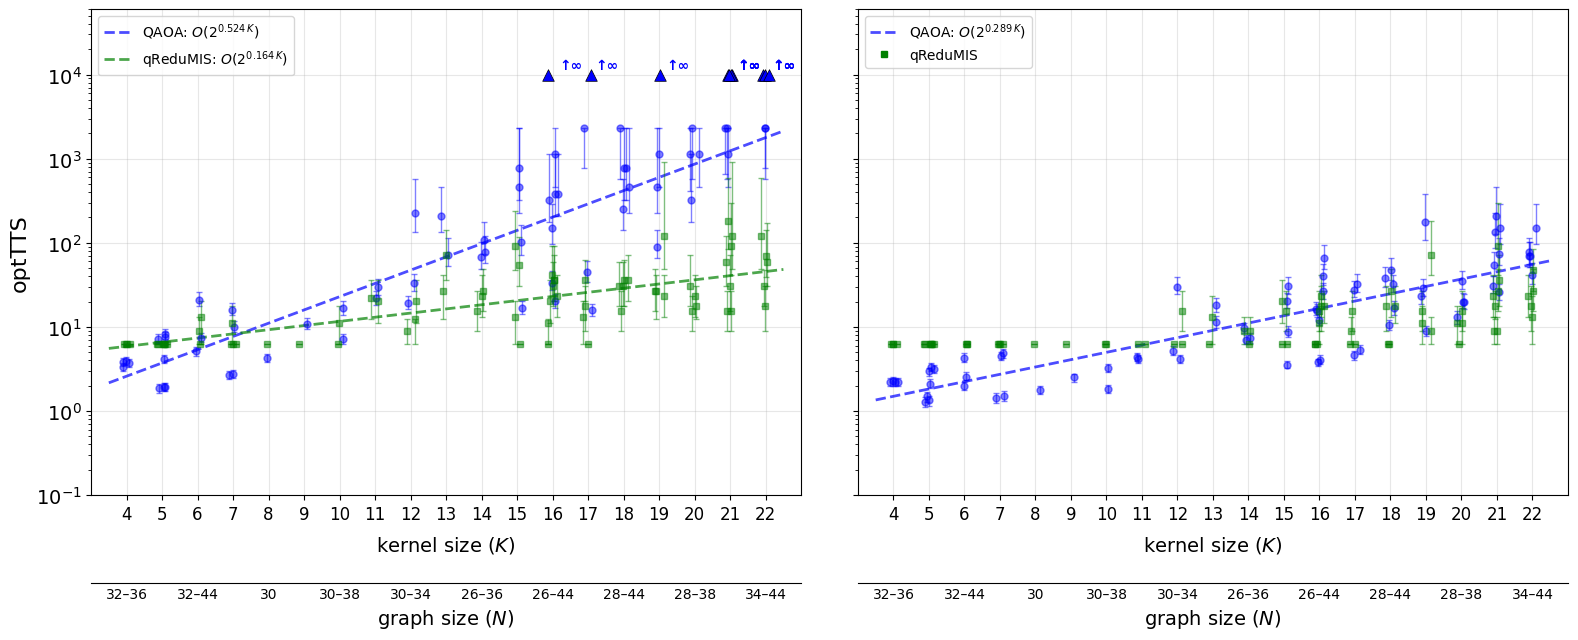

In [6]:
## ═══════════════════════════════════════════════════════════════
## Fig. 5 — optTTS vs kernel size — p=2 (left panel) and p=6 (right panel)
## ═══════════════════════════════════════════════════════════════
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 12,
})

def _exp2_model(K, C, a):
    """C * 2^(a * K)"""
    return C * 2 ** (a * K)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)

datasets_tts = [
    ("$p=2$", df_qaoa_p2, df_qr_p2),
    ("$p=6$", df_qaoa_p6, df_qr_p6),
]

for ax, (title_p, df_qaoa, df_qr) in zip(axes, datasets_tts):
    rng_j = np.random.default_rng(42)

    # Build K → N mapping
    dfk_all = pd.concat([_add_kernel_size(df_qaoa), _add_kernel_size(df_qr)],
                        ignore_index=True)
    K_TICKS = [int(k) for k in sorted(dfk_all["kernel_size"].unique())]
    n_range_per_k = (dfk_all.groupby("kernel_size")["N"]
                     .agg(["min", "max"]).reset_index())

    methods_panel = [
        ("QAOA",     df_qaoa, "blue",  "o"),
        ("qReduMIS", df_qr,   "green", "s"),
    ]

    for label, df, color, marker in methods_panel:
        dfk = _add_kernel_size(df)
        col = "boot_median"
        has_ci = (dfk["boot_ci_lo"].notna().any() and
                  dfk["boot_ci_hi"].notna().any() and
                  np.isfinite(dfk["boot_ci_lo"].dropna()).any())

        valid = dfk[np.isfinite(dfk[col])].copy()
        if valid.empty:
            continue

        # Per-instance points with CI
        jit = rng_j.uniform(-0.15, 0.15, size=len(valid))
        x_vals = valid["kernel_size"].values + jit
        y_vals = valid[col].values
        if has_ci:
            yerr_lo = (valid[col].values - valid["boot_ci_lo"].values).clip(min=0)
            yerr_hi = (valid["boot_ci_hi"].values - valid[col].values).clip(min=0)
        else:
            yerr_lo = yerr_hi = np.zeros(len(valid))

        ax.errorbar(x_vals, y_vals, yerr=[yerr_lo, yerr_hi],
                    fmt=marker, color=color, markersize=5, alpha=0.5,
                    ecolor=color, elinewidth=1.0, capsize=2, capthick=1.0,
                    zorder=5, linestyle="none", label=None)

        # Exponential fit (QAOA always; qReduMIS only for p=2)
        do_fit = (label != "qReduMIS") or (title_p == "$p=2$")
        if do_fit and len(valid) >= 2:
            x_all = valid["kernel_size"].values.astype(float)
            y_all = valid[col].values.astype(float)
            mask = y_all > 0
            a_fit, log2_C = np.polyfit(x_all[mask], np.log2(y_all[mask]), 1)
            x_dense = np.linspace(min(K_TICKS) - 0.5, max(K_TICKS) + 0.5, 200)
            ax.plot(x_dense, _exp2_model(x_dense, 2 ** log2_C, a_fit),
                    "--", color=color, linewidth=2, alpha=0.7,
                    label=f"{label}: $O(2^{{{a_fit:.3f} \\, K}})$")
        elif label == "qReduMIS":
            # No fit for qReduMIS p=6 — just add a legend entry
            ax.plot([], [], marker=marker, color=color, linestyle="none",
                    markersize=5, label="qReduMIS")

        # Mark ∞ instances
        inf_rows = dfk[~np.isfinite(dfk[col])]
        if not inf_rows.empty:
            Y_INF = 1e4
            ks_inf = inf_rows["kernel_size"].values
            jit_inf = rng_j.uniform(-0.15, 0.15, size=len(inf_rows))
            ax.scatter(ks_inf + jit_inf, [Y_INF] * len(ks_inf),
                       marker="^", s=70, color=color,
                       edgecolors="k", linewidths=0.5, zorder=10)
            for xk in ks_inf:
                ax.annotate("↑∞", (xk, Y_INF),
                            textcoords="offset points", xytext=(5, 4),
                            fontsize=10, fontweight="bold", color=color)

    # Axes formatting
    ax.set_xticks(K_TICKS)
    ax.set_xticklabels([str(k) for k in K_TICKS], fontsize=12)
    ax.set_xlim(min(K_TICKS) - 1, max(K_TICKS) + 1)
    ax.set_yscale("log")
    ax.set_xlabel("kernel size ($K$)", fontsize=14, labelpad=8)
    ax.legend(fontsize=10, frameon=True, loc="upper left")
    ax.grid(True, alpha=0.3)
    ax.set_ylim(1e-1, 6e4)

    # Second x-axis BELOW: graph size N intervals (every other tick)
    ax2 = ax.secondary_xaxis(-0.18)
    ax2.set_xticks(K_TICKS)
    bottom_labels = []
    for i, k in enumerate(K_TICKS):
        row = n_range_per_k[n_range_per_k["kernel_size"] == k]
        if i % 2 == 0 and not row.empty:
            nmin, nmax = int(row["min"].values[0]), int(row["max"].values[0])
            bottom_labels.append(f"{nmin}" if nmin == nmax else f"{nmin}–{nmax}")
        else:
            bottom_labels.append("")
    ax2.set_xticklabels(bottom_labels, fontsize=10)
    ax2.set_xlabel("graph size ($N$)", fontsize=14)
    ax2.tick_params(length=0)

axes[0].set_ylabel("optTTS", fontsize=16)

plt.tight_layout()
fig.subplots_adjust(bottom=0.22, wspace=0.08)
if SAVE_FIGURES:
    plt.savefig("figures/final_optTTS_qaoa_qredumis_remove_only_qshots5_rev.png", dpi=300, bbox_inches="tight")
plt.show()


In [7]:
# ── Table tab:individual-fits — OLS fit of log2(optTTS) = α + β·K ────────
from scipy import stats

fit_configs = [
    ("QAOA",     "2", df_qaoa_p2, True),
    ("qReduMIS", "2", df_qr_p2,   True),
    ("QAOA",     "6", df_qaoa_p6, True),
    ("qReduMIS", "6", df_qr_p6,   False),   # no fit expected
]

rows_latex = []
for method, p_val, df, do_fit in fit_configs:
    dfk = _add_kernel_size(df)
    col = "boot_median"
    valid = dfk[np.isfinite(dfk[col])].copy()

    if not do_fit or valid.empty or len(valid) < 3:
        rows_latex.append(
            f"{method} & {p_val} & "
            r"\multicolumn{3}{c}{\textit{No significant exponential fit}} \\"
        )
        continue

    x = valid["kernel_size"].values.astype(float)
    y = valid[col].values.astype(float)
    mask = y > 0
    x, y = x[mask], y[mask]
    log2_y = np.log2(y)

    slope, intercept, r_value, p_value, std_err = stats.linregress(x, log2_y)
    r2 = r_value ** 2

    # Format p-value
    if p_value < 1e-10:
        pval_str = r"${<}\,10^{-10}$"
    else:
        exp = int(np.floor(np.log10(p_value)))
        coeff = p_value / 10**exp
        pval_str = f"${coeff:.1f}\\times10^{{{exp}}}$"

    rows_latex.append(
        f"{method} & {p_val} & ${slope:.3f} \\pm {std_err:.3f}$ & "
        f"{r2:.2f} & {pval_str} \\\\"
    )

    print(f"{method:10s} p={p_val}:  β={slope:.4f} ± {std_err:.4f},  "
          f"R²={r2:.3f},  p={p_value:.2e},  n={len(x)}")

# Build full LaTeX table
latex_table = r"""\begin{table}[t]
\centering
\caption{Ordinary least-squares fits of
$\log_2 \widetilde{T} = \alpha + \beta\,K + \varepsilon$ for each
method and QAOA depth~$p$.}
\label{tab:individual-fits}
\begin{tabular}{llccc}
\toprule
Method   & $p$ & $\hat{\beta} \pm \mathrm{SE}$ & $R^{2}$
         & $p$-value ($\hat{\beta}$) \\
\midrule
""" + "\n".join(rows_latex[:2]) + r"""
\midrule
""" + "\n".join(rows_latex[2:]) + r"""
\bottomrule
\end{tabular}
\end{table}"""

print("\n" + latex_table)

QAOA       p=2:  β=0.5235 ± 0.0328,  R²=0.807,  p=1.94e-23,  n=63
qReduMIS   p=2:  β=0.1642 ± 0.0179,  R²=0.542,  p=1.13e-13,  n=73
QAOA       p=6:  β=0.2894 ± 0.0210,  R²=0.727,  p=1.06e-21,  n=73

\begin{table}[t]
\centering
\caption{Ordinary least-squares fits of
$\log_2 \widetilde{T} = \alpha + \beta\,K + \varepsilon$ for each
method and QAOA depth~$p$.}
\label{tab:individual-fits}
\begin{tabular}{llccc}
\toprule
Method   & $p$ & $\hat{\beta} \pm \mathrm{SE}$ & $R^{2}$
         & $p$-value ($\hat{\beta}$) \\
\midrule
QAOA & 2 & $0.524 \pm 0.033$ & 0.81 & ${<}\,10^{-10}$ \\
qReduMIS & 2 & $0.164 \pm 0.018$ & 0.54 & ${<}\,10^{-10}$ \\
\midrule
QAOA & 6 & $0.289 \pm 0.021$ & 0.73 & ${<}\,10^{-10}$ \\
qReduMIS & 6 & \multicolumn{3}{c}{\textit{No significant exponential fit}} \\
\bottomrule
\end{tabular}
\end{table}


In [8]:
# ── Δβ = β_QAOA − β_qReduMIS with two-sample t-test ──────────────────────

def _ols_fit(df_in):
    """Return (slope, se, x, log2_y) for finite boot_median entries."""
    dfk = _add_kernel_size(df_in)
    v = dfk[np.isfinite(dfk["boot_median"])].copy()
    x = v["kernel_size"].values.astype(float)
    y = v["boot_median"].values.astype(float)
    m = y > 0
    x, y = x[m], y[m]
    log2_y = np.log2(y)
    slope, intercept, r_val, p_val, se = stats.linregress(x, log2_y)
    return slope, se, x, log2_y

pairs = [
    ("p=2", df_qaoa_p2, df_qr_p2),
    ("p=6", df_qaoa_p6, None),       # qReduMIS p=6 has no fit
]

for p_label, df_q, df_r in pairs:
    b_q, se_q, x_q, y_q = _ols_fit(df_q)

    if df_r is None:
        print(f"\n── {p_label} ──")
        print(f"  QAOA β = {b_q:.4f} ± {se_q:.4f}")
        print(f"  qReduMIS: no significant exponential fit → Δβ not applicable")
        continue

    b_r, se_r, x_r, y_r = _ols_fit(df_r)

    delta_beta = b_q - b_r
    se_delta = np.sqrt(se_q**2 + se_r**2)              # Welch-style SE
    df_welch = (se_q**2 + se_r**2)**2 / (
        se_q**4 / (len(x_q) - 2) + se_r**4 / (len(x_r) - 2)
    )
    t_stat = delta_beta / se_delta
    p_value = 2 * stats.t.sf(abs(t_stat), df=df_welch)  # two-tailed

    print(f"\n── {p_label} ──")
    print(f"  β_QAOA     = {b_q:.4f} ± {se_q:.4f}  (n={len(x_q)})")
    print(f"  β_qReduMIS = {b_r:.4f} ± {se_r:.4f}  (n={len(x_r)})")
    print(f"  Δβ         = {delta_beta:.3f} ± {se_delta:.3f}")
    print(f"  t          = {t_stat:.2f},  df = {df_welch:.1f},  p = {p_value:.2e}")

    # LaTeX snippet
    if p_value < 1e-10:
        pval_tex = r"{<}\,10^{-10}"
    else:
        exp = int(np.floor(np.log10(p_value)))
        coeff = p_value / 10**exp
        pval_tex = f"{coeff:.1f} \\times 10^{{{exp}}}"

    print(f"""
\\begin{{multline}}
    \\Delta\\hat{{\\beta}}
    = \\hat{{\\beta}}_{{\\text{{QAOA}}}} - \\hat{{\\beta}}_{{\\text{{qReduMIS}}}}
    = {delta_beta:.3f} \\pm {se_delta:.3f}, \\\\
    t = {t_stat:.2f},
    \\qquad
    p = ${pval_tex}$,
\\end{{multline}}""")


── p=2 ──
  β_QAOA     = 0.5235 ± 0.0328  (n=63)
  β_qReduMIS = 0.1642 ± 0.0179  (n=73)
  Δβ         = 0.359 ± 0.037
  t          = 9.61,  df = 95.4,  p = 1.07e-15

\begin{multline}
    \Delta\hat{\beta}
    = \hat{\beta}_{\text{QAOA}} - \hat{\beta}_{\text{qReduMIS}}
    = 0.359 \pm 0.037, \\
    t = 9.61,
    \qquad
    p = ${<}\,10^{-10}$,
\end{multline}

── p=6 ──
  QAOA β = 0.2894 ± 0.0210
  qReduMIS: no significant exponential fit → Δβ not applicable


## Fig. 11 — QPU calls to solution — qReduMIS (p=2 vs p=6)

Violin plot of `mean_opt_calls` (average number of QPU calls needed to find the optimal solution) as a function of kernel size.

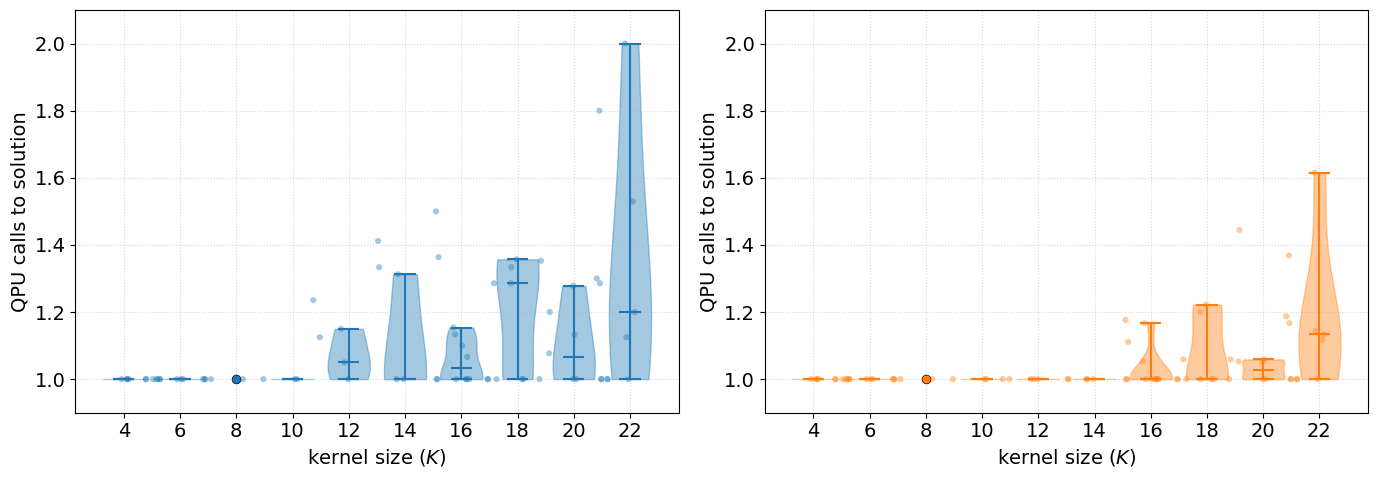

In [9]:
# =============================================================================
# Violin plot of mean_opt_calls as a function of kernel size
# for qReduMIS at p=2 and p=6
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

col = "mean_opt_calls"
K_TICKS = [4, 6, 8, 10, 12, 14, 16, 18, 20, 22]

datasets = [
    ("qReduMIS $p=2$", df_qr_p2, "tab:blue", axes[0]),
    ("qReduMIS $p=6$", df_qr_p6, "tab:orange", axes[1]),
]

for title, df, color, ax in datasets:
    dfk = _add_kernel_size(df)
    mask = dfk[col].notna() & np.isfinite(dfk[col]) & (dfk[col] > 0)
    dfk_valid = dfk.loc[mask].copy()
    dfk_valid["kernel_size"] = dfk_valid["kernel_size"].astype(int)

    # Collect data per K tick (only ticks with data)
    violin_data = []
    violin_positions = []
    for k in K_TICKS:
        vals = dfk_valid.loc[dfk_valid["kernel_size"] == k, col].values
        if len(vals) >= 2:  # need at least 2 points for a violin
            violin_data.append(vals)
            violin_positions.append(k)
        elif len(vals) == 1:
            # single point: just scatter it
            ax.scatter(k, vals[0], color=color, s=40, zorder=5, edgecolors="k", linewidths=0.5)

    if violin_data:
        parts = ax.violinplot(violin_data, positions=violin_positions,
                              showmedians=True, showextrema=True, widths=1.5)
        # Style the violins
        for pc in parts["bodies"]:
            pc.set_facecolor(color)
            pc.set_alpha(0.4)
            pc.set_edgecolor(color)
        for key in ["cmins", "cmaxes", "cmedians", "cbars"]:
            if key in parts:
                parts[key].set_color(color)
                parts[key].set_linewidth(1.5)

    # Overlay individual points with jitter
    rng_v = np.random.default_rng(42)
    jit = rng_v.uniform(-0.3, 0.3, size=len(dfk_valid))
    ax.scatter(dfk_valid["kernel_size"].values + jit, dfk_valid[col].values,
               alpha=0.4, s=20, color=color, edgecolors="none", zorder=3)

    ax.set_ylim([0.9, 2.1])
    ax.set_xticks(K_TICKS)
    ax.set_xticklabels([str(k) for k in K_TICKS])
    ax.set_xlabel("kernel size ($K$)")
    ax.set_ylabel("QPU calls to solution")
    ax.grid(True, which="both", ls=":", alpha=0.5)

fig.tight_layout()
if SAVE_FIGURES:
    plt.savefig("figures/final_qpu_calls_qredumis_remove_only_qshots5.png", dpi=300, bbox_inches="tight")
plt.show()

## Fig. 6 — Weighted energy (expected IS size from counts)

For each instance we compute the **expected independent-set size** weighted by measurement counts:

$$\langle |IS| \rangle = \frac{\sum_i |IS_i| \times c_i}{\sum_i c_i}$$

- **QAOA**: uses `clean_counts` (shots on the kernel) → normalised by kernel MIS (baseline)
- **qReduMIS**: uses `prefixup_counts` (shots per QPU call, pooled across all cshots & iterations) → normalised by full-graph MIS

In [10]:
## ═══════════════════════════════════════════════════════════════
## Load weighted-average IS sizes from count files (results_73)
## ═══════════════════════════════════════════════════════════════

# ── Helper: load QAOA clean_counts → weighted avg IS per instance ────
def load_qaoa_weighted_energy(db_path):
    """Load from single QAOA DB + sibling counts/ folder.
    Returns DataFrame with N, seed, weighted_avg_IS, gt_mis, weighted_ar."""
    db_dir = os.path.dirname(db_path)
    counts_dir = os.path.join(db_dir, "counts")

    # Get baselines from consolidated_results/benchmarks.csv
    baselines = {}
    for d in D.db_records(db_path):
        key = (d["N"], d["seed"])
        if key not in baselines:
            baselines[key] = d["baseline"]

    records = []
    instances = D.counts_instances(counts_dir)
    if not instances:
        return pd.DataFrame(records)

    for N, seed, p_val in instances:
        key = (N, seed)
        cc = D.counts_records(counts_dir, N, seed, p_val)
        total_shots = sum(e["count"] for e in cc)
        if total_shots == 0:
            continue
        weighted_sum = sum(len(e["nodes"]) * e["count"] for e in cc)
        avg_is = weighted_sum / total_shots
        bl = baselines.get(key)
        if bl is None or bl == 0:
            continue
        records.append({
            "N": N, "seed": seed,
            "weighted_avg_IS": avg_is,
            "gt_mis": bl,
            "weighted_ar": avg_is / bl,
        })
    return pd.DataFrame(records)

# ── Helper: qReduMIS final |W| per cshot → avg IS per instance ───────
def load_qredumis_weighted_energy(inter_dir, gt_dict):
    """Each cshot reports a solution W. Weighted avg = sum(|W_i|)/cshots / MIS.

    Reads ``consolidated_results/iterations.csv`` (the per-iteration table) instead of
    the ~85k ``info_*.json`` files it was consolidated from.
    """
    return D.weighted_energy_iterations(inter_dir, gt_dict)

# ── p=2 ──────────────────────────────────────────────────────────────
we_qaoa_p2 = load_qaoa_weighted_energy(QAOA_P2_DB)
we_qr_p2 = load_qredumis_weighted_energy(
    os.path.join(RESULTS_73, f"qredumis_p2_{RUN_DATE}", "intermediate_iterations"),
    gt_full,
)

# ── p=6 ──────────────────────────────────────────────────────────────
we_qaoa_p6 = load_qaoa_weighted_energy(QAOA_P6_DB)
we_qr_p6 = load_qredumis_weighted_energy(
    os.path.join(RESULTS_73, f"qredumis_p6_{RUN_DATE}", "intermediate_iterations"),
    gt_full,
)

print("Weighted energy data loaded:")
print(f"  QAOA p=2:     {len(we_qaoa_p2)} instances, "
      f"mean ⟨|IS|⟩/MIS = {we_qaoa_p2['weighted_ar'].mean():.3f}" if len(we_qaoa_p2) else "  QAOA p=2: 0 instances")
print(f"  qReduMIS p=2: {len(we_qr_p2)} instances, "
      f"mean ⟨|IS|⟩/MIS = {we_qr_p2['weighted_ar'].mean():.3f}" if len(we_qr_p2) else "  qReduMIS p=2: 0 instances")
print(f"  QAOA p=6:     {len(we_qaoa_p6)} instances, "
      f"mean ⟨|IS|⟩/MIS = {we_qaoa_p6['weighted_ar'].mean():.3f}" if len(we_qaoa_p6) else "  QAOA p=6: 0 instances")
print(f"  qReduMIS p=6: {len(we_qr_p6)} instances, "
      f"mean ⟨|IS|⟩/MIS = {we_qr_p6['weighted_ar'].mean():.3f}" if len(we_qr_p6) else "  qReduMIS p=6: 0 instances")

Weighted energy data loaded:
  QAOA p=2:     73 instances, mean ⟨|IS|⟩/MIS = 0.564
  qReduMIS p=2: 73 instances, mean ⟨|IS|⟩/MIS = 0.970
  QAOA p=6:     73 instances, mean ⟨|IS|⟩/MIS = 0.780
  qReduMIS p=6: 73 instances, mean ⟨|IS|⟩/MIS = 0.989


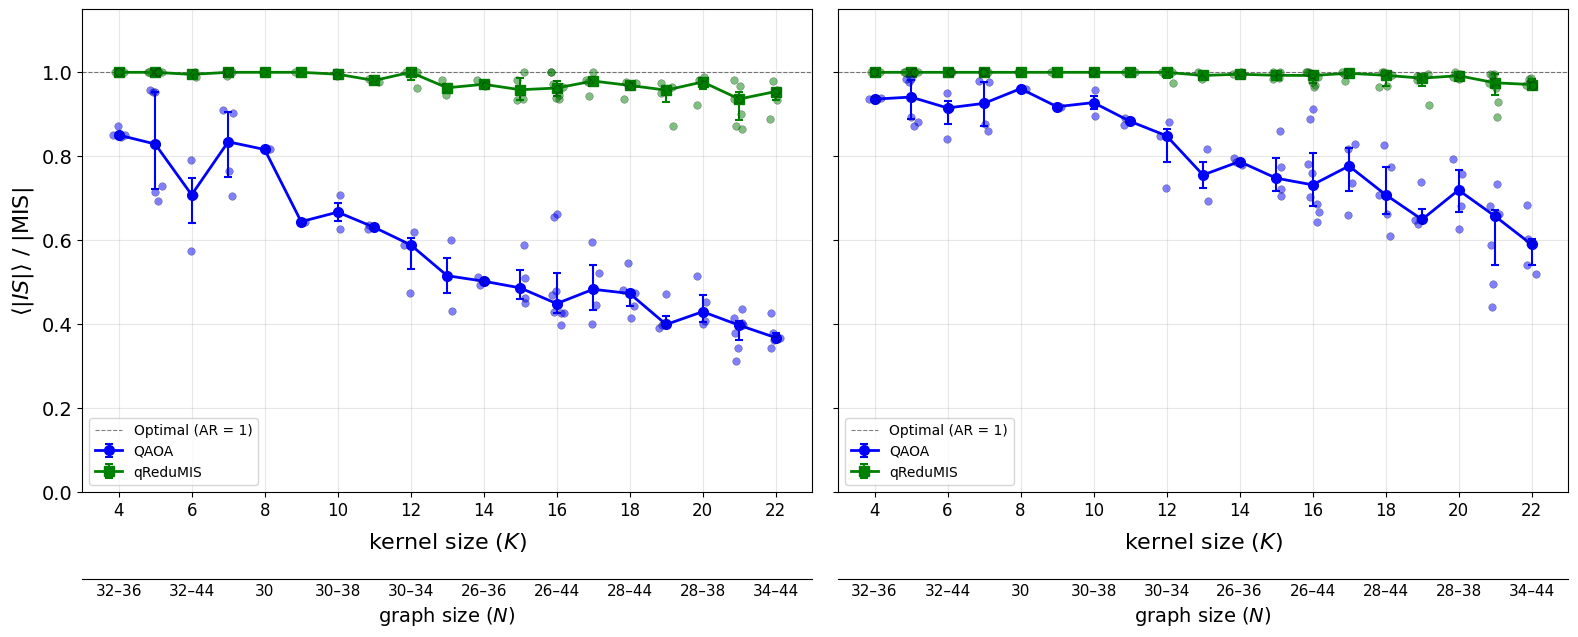


Weighted energy summary (median ± IQR) per kernel size:

  $p=2$:
    QAOA        K= 4  median=0.851  mean=0.855  n=4
    QAOA        K= 5  median=0.829  mean=0.833  n=7
    QAOA        K= 6  median=0.708  mean=0.690  n=3
    QAOA        K= 7  median=0.834  mean=0.821  n=4
    QAOA        K= 8  median=0.816  mean=0.816  n=1
    QAOA        K= 9  median=0.644  mean=0.644  n=1
    QAOA        K=10  median=0.667  mean=0.667  n=2
    QAOA        K=11  median=0.631  mean=0.631  n=2
    QAOA        K=12  median=0.589  mean=0.561  n=3
    QAOA        K=13  median=0.515  mean=0.515  n=2
    QAOA        K=14  median=0.502  mean=0.503  n=3
    QAOA        K=15  median=0.486  mean=0.503  n=4
    QAOA        K=16  median=0.449  mean=0.492  n=8
    QAOA        K=17  median=0.483  mean=0.491  n=4
    QAOA        K=18  median=0.473  mean=0.471  n=5
    QAOA        K=19  median=0.399  mean=0.415  n=4
    QAOA        K=20  median=0.429  mean=0.443  n=4
    QAOA        K=21  median=0.397  mean=0.383  n

In [11]:
## ═══════════════════════════════════════════════════════════════
## Weighted AR (⟨|IS|⟩ / MIS) vs kernel size — p=2 (left) and p=6 (right)
## ═══════════════════════════════════════════════════════════════

plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 12,
})

K_TICKS_WE = [4, 6, 8, 10, 12, 14, 16, 18, 20, 22]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
fig.subplots_adjust(bottom=0.22, wspace=0.08)

datasets_we = [
    ("$p=2$", we_qaoa_p2, we_qr_p2),
    ("$p=6$", we_qaoa_p6, we_qr_p6),
]

for ax, (title_p, we_qaoa, we_qr) in zip(axes, datasets_we):
    rng_we = np.random.default_rng(42)

    methods = [
        ("QAOA",     we_qaoa, "blue",  "o"),
        ("qReduMIS", we_qr,   "green", "s"),
    ]

    # Build K → N range mapping for bottom axis
    all_dfk = pd.concat([_add_kernel_size_safe(we_qaoa),
                         _add_kernel_size_safe(we_qr)], ignore_index=True)
    n_rng = (all_dfk.groupby("kernel_size")["N"]
             .agg(["min", "max"]).reset_index())

    for label, we_df, color, marker in methods:
        dfk = _add_kernel_size_safe(we_df)
        if dfk.empty:
            continue

        # Aggregate: median + IQR per kernel size
        agg = (dfk.groupby("kernel_size")["weighted_ar"]
               .agg(median="median",
                    q25=lambda x: x.quantile(0.25),
                    q75=lambda x: x.quantile(0.75),
                    count="count")
               .reset_index())

        # Per-instance jittered points
        jit = rng_we.uniform(-0.2, 0.2, size=len(dfk))
        ax.scatter(dfk["kernel_size"].values + jit,
                   dfk["weighted_ar"].values,
                   alpha=0.5, s=30, color=color, edgecolors="k",
                   linewidths=0.3, zorder=6)

        # Median with IQR error bars
        yerr_lo = (agg["median"] - agg["q25"]).values
        yerr_hi = (agg["q75"] - agg["median"]).values
        ax.errorbar(agg["kernel_size"], agg["median"],
                    yerr=[yerr_lo, yerr_hi],
                    fmt=marker + "-", color=color, markersize=7, linewidth=2,
                    ecolor=color, elinewidth=1.5, capsize=3, capthick=1.5,
                    zorder=5, label=label)

    ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--", alpha=0.5,
               label="Optimal (AR = 1)")
    ax.set_xticks(K_TICKS_WE)
    ax.set_xticklabels([str(k) for k in K_TICKS_WE], fontsize=12)
    ax.set_xlim(min(K_TICKS_WE) - 1, max(K_TICKS_WE) + 1)
    ax.set_ylim(0, 1.15)
    ax.set_xlabel("kernel size ($K$)", fontsize=16, labelpad=8)
    ax.legend(fontsize=10, frameon=True, loc="lower left")
    ax.grid(True, alpha=0.3)

    # Second x-axis: graph size N
    ax2 = ax.secondary_xaxis(-0.18)
    ax2.set_xticks(K_TICKS_WE)
    blabels = []
    for k in K_TICKS_WE:
        row = n_rng[n_rng["kernel_size"] == k]
        if not row.empty:
            nmin, nmax = int(row["min"].values[0]), int(row["max"].values[0])
            blabels.append(f"{nmin}" if nmin == nmax else f"{nmin}–{nmax}")
        else:
            blabels.append("")
    ax2.set_xticklabels(blabels, fontsize=11)
    ax2.set_xlabel("graph size ($N$)", fontsize=14)
    ax2.tick_params(length=0)

axes[0].set_ylabel(r"$\langle |IS| \rangle$ / |MIS|", fontsize=16)

plt.tight_layout()
if SAVE_FIGURES:
    plt.savefig("figures/final_weighted_energy_vs_kernel_size_remove_only_qshots5.png", dpi=300, bbox_inches="tight")
plt.show()

# ── Summary statistics ───────────────────────────────────────────────
print("\nWeighted energy summary (median ± IQR) per kernel size:")
for title_p, we_qaoa, we_qr in datasets_we:
    print(f"\n  {title_p}:")
    for label, we_df in [("QAOA", we_qaoa), ("qReduMIS", we_qr)]:
        dfk = _add_kernel_size_safe(we_df)
        if dfk.empty:
            continue
        agg = (dfk.groupby("kernel_size")["weighted_ar"]
               .agg(["median", "mean", "count"]).reset_index())
        for _, r in agg.iterrows():
            print(f"    {label:10s}  K={int(r['kernel_size']):2d}  "
                  f"median={r['median']:.3f}  mean={r['mean']:.3f}  n={int(r['count'])}")

## Fig. 10 — Success probability $p_S$

**QAOA**: $p_S = \texttt{pmis}$ = fraction of the 500 quantum shots whose IS size equals the ground-truth MIS on the kernel (stored as `pmis` in the QAOA DB, see `opt_tts_estimator._estimate_annealing`).

**qReduMIS**: $p_S$ = fraction of the 20 classical shots (cshots) whose final IS size equals the ground-truth MIS on the full graph (analogous to `opt_tts_estimator._estimate_redumis` success criterion).

In [12]:
## ═══════════════════════════════════════════════════════════════
## Load success probabilities from SQLite databases (results_73)
## ═══════════════════════════════════════════════════════════════

def load_qaoa_success_prob(db_path):
    """QAOA: pmis = fraction of shots that found the optimal IS on the kernel."""
    records = []
    for d in D.db_records(db_path):
        records.append({
            "N": d["N"], "seed": d["seed"],
            "p_success": d["pmis"],
            "gt_mis": d["baseline"],
        })
    return pd.DataFrame(records)


def load_qredumis_success_prob(db_path, gt_dict):
    """qReduMIS: fraction of cshots whose final IS size == ground-truth MIS."""
    from collections import defaultdict
    cshot_sizes = defaultdict(list)
    for d in D.db_records(db_path):
        key = (d["N"], d["seed"])
        mis_size = len(d["atom positions MIS"])
        cshot_sizes[key].append(mis_size)

    records = []
    for (N, seed), sizes_list in cshot_sizes.items():
        gt_size = gt_dict.get((N, seed))
        if gt_size is None or gt_size == 0:
            continue
        n_success = sum(1 for s in sizes_list if s == gt_size)
        records.append({
            "N": N, "seed": seed,
            "p_success": n_success / len(sizes_list),
            "n_cshots": len(sizes_list),
            "n_success": n_success,
            "gt_mis": gt_size,
        })
    return pd.DataFrame(records)


# ── p=2 ──────────────────────────────────────────────────────────────
sp_qaoa_p2 = load_qaoa_success_prob(QAOA_P2_DB)
sp_qr_p2   = load_qredumis_success_prob(QR_P2_DB, gt_full)

# ── p=6 ──────────────────────────────────────────────────────────────
sp_qaoa_p6 = load_qaoa_success_prob(QAOA_P6_DB)
sp_qr_p6   = load_qredumis_success_prob(QR_P6_DB, gt_full)

print("Success probability data loaded:")
print(f"  QAOA p=2:     {len(sp_qaoa_p2)} instances, "
      f"mean p_S = {sp_qaoa_p2['p_success'].mean():.3f}")
print(f"  qReduMIS p=2: {len(sp_qr_p2)} instances, "
      f"mean p_S = {sp_qr_p2['p_success'].mean():.3f}")
print(f"  QAOA p=6:     {len(sp_qaoa_p6)} instances, "
      f"mean p_S = {sp_qaoa_p6['p_success'].mean():.3f}")
print(f"  qReduMIS p=6: {len(sp_qr_p6)} instances, "
      f"mean p_S = {sp_qr_p6['p_success'].mean():.3f}")

Success probability data loaded:
  QAOA p=2:     73 instances, mean p_S = 0.205
  qReduMIS p=2: 73 instances, mean p_S = 0.772
  QAOA p=6:     73 instances, mean p_S = 0.439
  qReduMIS p=6: 73 instances, mean p_S = 0.908


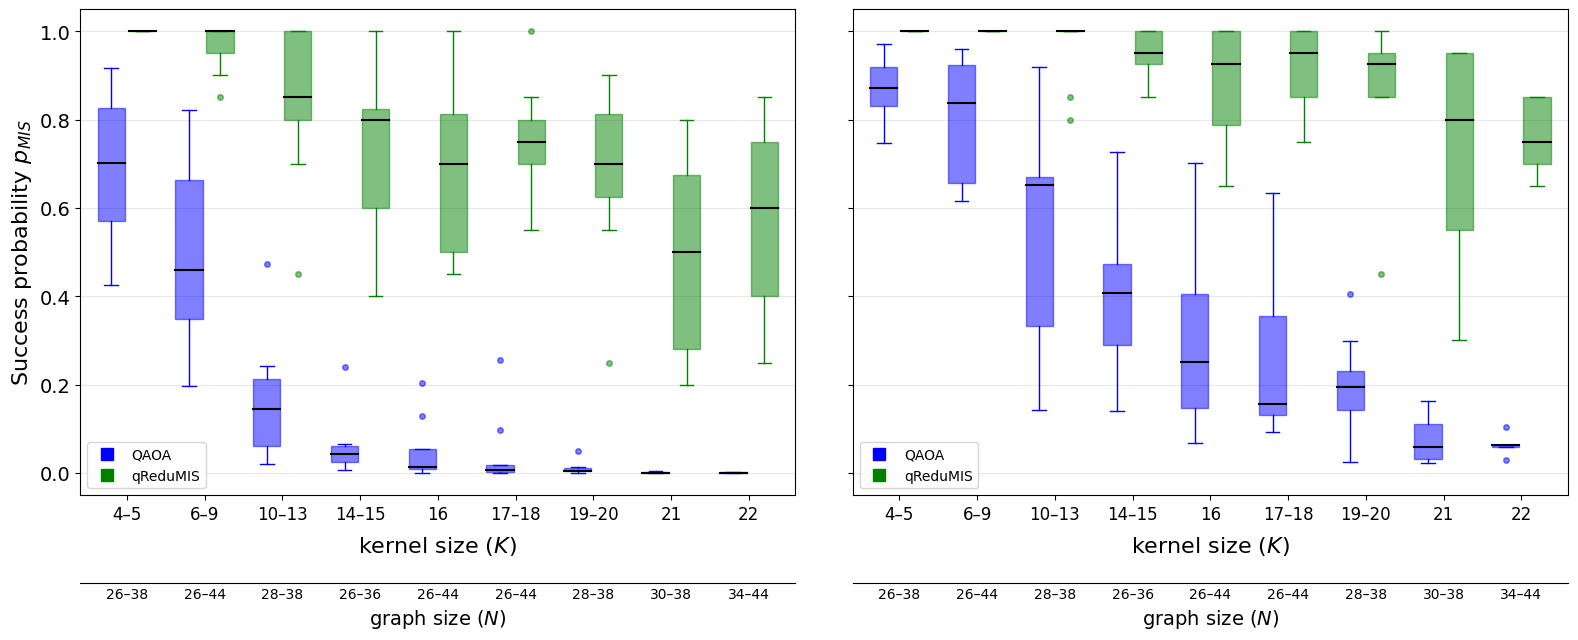

,QAOA p=2,qReduMIS p=2,QAOA p=6,qReduMIS p=6
K interval,,,,
4–5,0.702,1.00,0.872,1.000
6–9,0.460,1.00,0.838,1.000
10–13,0.144,0.85,0.652,1.000
14–15,0.044,0.80,0.408,0.950
16,0.013,0.70,0.252,0.925
17–18,0.006,0.75,0.156,0.950
19–20,0.004,0.70,0.194,0.925
21,0.000,0.50,0.060,0.800
22,0.000,0.60,0.064,0.750


In [13]:
## ═══════════════════════════════════════════════════════════════
## Fig. 10 — Success probability, box plot by kernel-size intervals
## ═══════════════════════════════════════════════════════════════

# Kernel-size bins (closed intervals) — also used by Fig. 8, Fig. 9 and
# Table tab:num_seeds_mkt_emulator below.
K_BINS = [(4, 5), (6, 9), (10, 13), (14, 15), (16, 16),
          (17, 18), (19, 20), (21, 21), (22, 22)]

def _bin_label(lo, hi):
    return f"{lo}" if lo == hi else f"{lo}–{hi}"

BIN_LABELS = [_bin_label(lo, hi) for lo, hi in K_BINS]

def _assign_bin(k):
    """Return the bin index (0-based) for kernel size k, or -1."""
    for i, (lo, hi) in enumerate(K_BINS):
        if lo <= k <= hi:
            return i
    return -1


def _n_range_label(k_lo, k_hi, n_rng):
    """'Nmin–Nmax' of the input graphs whose kernel size falls in [k_lo, k_hi]."""
    rows = n_rng[(n_rng["kernel_size"] >= k_lo) & (n_rng["kernel_size"] <= k_hi)]
    if rows.empty:
        return ""
    nmin, nmax = int(rows["min"].min()), int(rows["max"].max())
    return f"{nmin}" if nmin == nmax else f"{nmin}–{nmax}"


plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 14, 'legend.fontsize': 12,
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)

datasets_sp_box = [
    ("$p=2$", sp_qaoa_p2, sp_qr_p2),
    ("$p=6$", sp_qaoa_p6, sp_qr_p6),
]

box_width = 0.35

for ax, (title_p, sp_qaoa, sp_qr) in zip(axes, datasets_sp_box):

    methods = [
        ("QAOA",     sp_qaoa, "blue",  -0.2),
        ("qReduMIS", sp_qr,   "green",  0.2),
    ]

    # K → N range mapping from all data in this panel
    all_dfk = pd.concat([_add_kernel_size_safe(sp_qaoa),
                         _add_kernel_size_safe(sp_qr)], ignore_index=True)
    n_rng = (all_dfk.groupby("kernel_size")["N"]
             .agg(["min", "max"]).reset_index())

    for label, sp_df, color, offset in methods:
        dfk = _add_kernel_size_safe(sp_df)
        if dfk.empty:
            continue
        dfk["kbin"] = dfk["kernel_size"].apply(_assign_bin)
        dfk = dfk[dfk["kbin"] >= 0]

        box_data = [dfk.loc[dfk["kbin"] == i, "p_success"].values
                    for i in range(len(K_BINS))]
        positions = [i + offset for i in range(len(K_BINS))]

        bp = ax.boxplot(
            box_data, positions=positions, widths=box_width,
            patch_artist=True, showfliers=True, manage_ticks=False,
        )
        for patch in bp["boxes"]:
            patch.set_facecolor(color)
            patch.set_alpha(0.5)
            patch.set_edgecolor(color)
        for element in ("whiskers", "caps"):
            for line in bp[element]:
                line.set_color(color)
        for median_line in bp["medians"]:
            median_line.set_color("black")
            median_line.set_linewidth(1.5)
        for flier in bp["fliers"]:
            flier.set(marker="o", markerfacecolor=color,
                      markeredgecolor=color, markersize=4, alpha=0.5)

        # Proxy artist for the legend
        ax.plot([], [], "s", color=color, alpha=1.0, markersize=8, label=label)

    ax.set_xticks(range(len(K_BINS)))
    ax.set_xticklabels(BIN_LABELS, fontsize=12)
    ax.set_xlim(-0.6, len(K_BINS) - 0.4)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("kernel size ($K$)", fontsize=16, labelpad=8)
    ax.legend(fontsize=10, frameon=True, loc="lower left")
    ax.grid(True, alpha=0.3, axis="y")

    # Second x-axis BELOW: graph size N range per bin
    ax2 = ax.secondary_xaxis(-0.18)
    ax2.set_xticks(range(len(K_BINS)))
    ax2.set_xticklabels([_n_range_label(lo, hi, n_rng) for lo, hi in K_BINS],
                        fontsize=10)
    ax2.set_xlabel("graph size ($N$)", fontsize=14)
    ax2.tick_params(length=0)

axes[0].set_ylabel("Success probability $p_{MIS}$", fontsize=16)

plt.tight_layout()
fig.subplots_adjust(bottom=0.22, wspace=0.08)
if SAVE_FIGURES:
    plt.savefig("figures/final_success_prob_boxplot_best_postproc.png", dpi=300, bbox_inches="tight")
plt.show()

# ── Median P_MIS per kernel-size interval (quoted in the appendix text) ──
sp_median = {}
for name, sp_df in [("QAOA p=2", sp_qaoa_p2), ("qReduMIS p=2", sp_qr_p2),
                    ("QAOA p=6", sp_qaoa_p6), ("qReduMIS p=6", sp_qr_p6)]:
    dfk = _add_kernel_size_safe(sp_df)
    dfk["kbin"] = dfk["kernel_size"].apply(_assign_bin)
    sp_median[name] = dfk[dfk["kbin"] >= 0].groupby("kbin")["p_success"].median()
sp_median = pd.DataFrame(sp_median).rename(index=dict(enumerate(BIN_LABELS)))
sp_median.index.name = "K interval"
sp_median.round(3)


## Testbed characterisation per kernel-size interval

Uses the same `K_BINS` as Fig. 10.

- Table `tab:num_seeds_mkt_emulator`: number of instances per interval.
- Fig. 8: distribution of the (first) kernel size (top) and kernel density (bottom) per interval, with the input-graph size range $N$ on the secondary axis.
- Fig. 9: % of instances with optTTS $=\infty$ per interval and method, annotated with the median optTTS (computed over `boot_median`, infinities included).

In [14]:
## ═══════════════════════════════════════════════════════════════
## Per-instance testbed table: N, seed, kernel size, kernel density
## + Table tab:num_seeds_mkt_emulator
## ═══════════════════════════════════════════════════════════════
def _compute_kernel_density(N, seed):
    fpath = _find_graph_file(N, seed)
    if fpath is None:
        return np.nan
    Gk, _removed, _selected = Reducer().reduce(nx.read_graphml(fpath).copy())
    return nx.density(Gk)

df_testbed = pd.DataFrame(
    [{"N": N, "seed": seed, "kernel_size": ks} for (N, seed), ks in kernel_size_map.items()]
)
df_testbed["density"] = [_compute_kernel_density(N, s)
                         for N, s in zip(df_testbed["N"], df_testbed["seed"])]
df_testbed["kbin"] = df_testbed["kernel_size"].apply(_assign_bin)
df_testbed = df_testbed[df_testbed["kbin"] >= 0].sort_values(["kernel_size", "N", "seed"])
n_rng_testbed = (df_testbed.groupby("kernel_size")["N"]
                 .agg(["min", "max"]).reset_index())

_counts = df_testbed.groupby("kbin").size().reindex(range(len(K_BINS)), fill_value=0)
seeds_tbl = pd.DataFrame(
    {"num. seeds": _counts.values,
     "N range": [_n_range_label(lo, hi, n_rng_testbed) for lo, hi in K_BINS]},
    index=pd.Index(BIN_LABELS, name="kernel-size interval"),
)
print(f"Total instances: {seeds_tbl['num. seeds'].sum()}")
seeds_tbl


Total instances: 73


,num. seeds,N range
kernel-size interval,,
4–5,11,26–38
6–9,9,26–44
10–13,9,28–38
14–15,7,26–36
16,8,26–44
17–18,9,26–44
19–20,8,28–38
21,7,30–38
22,5,34–44


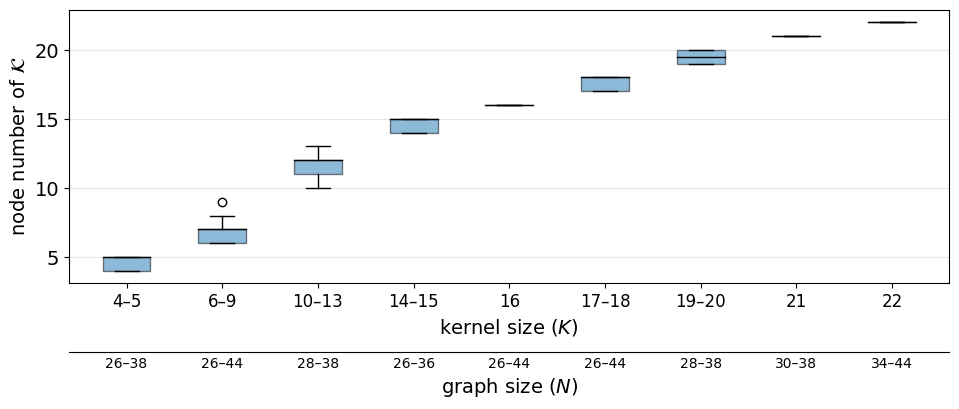

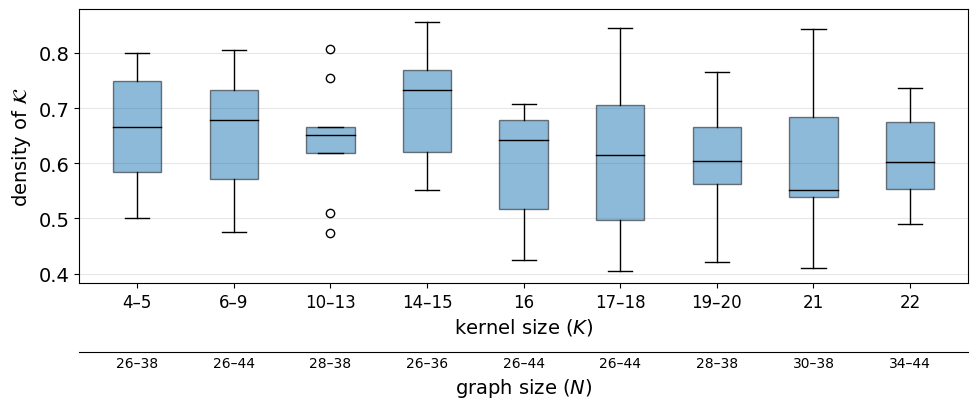

In [15]:
## ═══════════════════════════════════════════════════════════════
## Fig. 8 — kernel size (top) and kernel density (bottom) per interval
## ═══════════════════════════════════════════════════════════════
for col, ylabel, fname in [
    ("kernel_size", r"node number of $\mathcal{K}$", "distribution_kernel_size_box.png"),
    ("density",     r"density of $\mathcal{K}$",     "distribution_kernel_density_box.png"),
]:
    fig, ax = plt.subplots(figsize=(10, 4.5))
    data = [df_testbed.loc[df_testbed["kbin"] == i, col].values for i in range(len(K_BINS))]
    bp = ax.boxplot(data, positions=range(len(K_BINS)), widths=0.5,
                    patch_artist=True, manage_ticks=False)
    for patch in bp["boxes"]:
        patch.set_facecolor("tab:blue")
        patch.set_alpha(0.5)
    for median_line in bp["medians"]:
        median_line.set_color("black")

    ax.set_xticks(range(len(K_BINS)))
    ax.set_xticklabels(BIN_LABELS, fontsize=12)
    ax.set_xlim(-0.6, len(K_BINS) - 0.4)
    ax.set_xlabel("kernel size ($K$)", fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.grid(True, alpha=0.3, axis="y")

    ax2 = ax.secondary_xaxis(-0.25)
    ax2.set_xticks(range(len(K_BINS)))
    ax2.set_xticklabels([_n_range_label(lo, hi, n_rng_testbed) for lo, hi in K_BINS],
                        fontsize=10)
    ax2.set_xlabel("graph size ($N$)", fontsize=14)
    ax2.tick_params(length=0)

    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(f"figures/{fname}", dpi=300, bbox_inches="tight")
    plt.show()


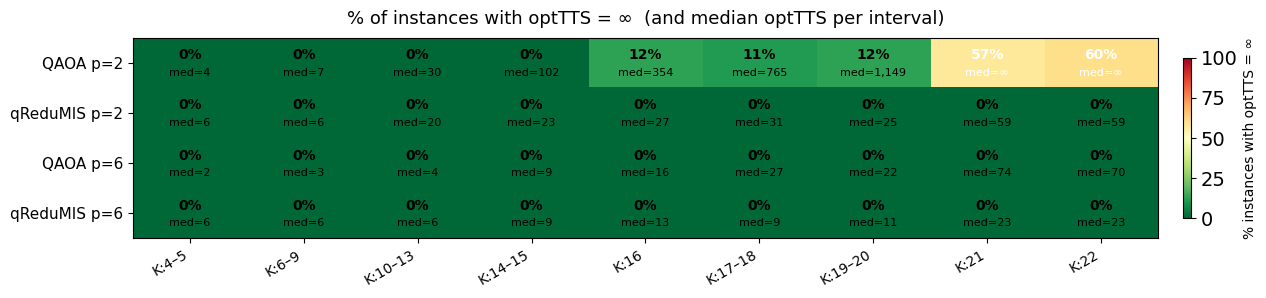

,4–5,6–9,10–13,14–15,16,17–18,19–20,21,22
QAOA p=2,0.0,0.0,0.0,0.0,12.0,11.0,12.0,57.0,60.0
qReduMIS p=2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
QAOA p=6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
qReduMIS p=6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
## ═══════════════════════════════════════════════════════════════
## Fig. 9 — % of instances with optTTS = ∞ (and median optTTS) per interval
## ═══════════════════════════════════════════════════════════════
series_order = ["QAOA p=2", "qReduMIS p=2", "QAOA p=6", "qReduMIS p=6"]
series_dfs = dict(zip(series_order, [df_qaoa_p2, df_qr_p2, df_qaoa_p6, df_qr_p6]))

pct_inf = np.full((len(series_order), len(K_BINS)), np.nan)
med_tts = np.full((len(series_order), len(K_BINS)), np.nan)
for i, name in enumerate(series_order):
    dfk = _add_kernel_size(series_dfs[name])
    dfk["kbin"] = dfk["kernel_size"].apply(_assign_bin)
    for j in range(len(K_BINS)):
        vals = dfk.loc[dfk["kbin"] == j, "boot_median"].values.astype(float)  # includes inf
        if len(vals):
            pct_inf[i, j] = 100 * np.mean(~np.isfinite(vals))
            med_tts[i, j] = np.median(vals)

fig, ax = plt.subplots(figsize=(14, 3.2))
im = ax.imshow(pct_inf, cmap="RdYlGn_r", vmin=0, vmax=100, aspect="auto")
for i in range(len(series_order)):
    for j in range(len(K_BINS)):
        if np.isnan(pct_inf[i, j]):
            continue
        med_str = "\u221e" if np.isinf(med_tts[i, j]) else f"{med_tts[i, j]:,.0f}"
        color = "white" if pct_inf[i, j] > 50 else "black"
        ax.text(j, i - 0.15, f"{pct_inf[i, j]:.0f}%", ha="center", va="center",
                fontsize=10, fontweight="bold", color=color)
        ax.text(j, i + 0.2, f"med={med_str}", ha="center", va="center",
                fontsize=8, color=color)

ax.set_xticks(range(len(K_BINS)))
ax.set_xticklabels([f"K:{lbl}" for lbl in BIN_LABELS], rotation=30, ha="right", fontsize=10)
ax.set_yticks(range(len(series_order)))
ax.set_yticklabels(series_order, fontsize=11)
ax.set_title("% of instances with optTTS = \u221e  (and median optTTS per interval)",
             fontsize=13, pad=10)
cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cbar.set_label("% instances with optTTS = \u221e", fontsize=10)

plt.tight_layout()
if SAVE_FIGURES:
    plt.savefig("figures/optTTS_inf_report_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

pd.DataFrame(pct_inf, index=series_order, columns=BIN_LABELS).round(0)
